# Notebook 2 - Resumindo Dados de uma Base de Marketing (Análise Bivariada)

# Objetivos

1. Explorar técnicas de correlação e associação;


In [1]:
# Imports
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
import math

# adiciona diretório raiz do projeto ao sys.path
sys.path.insert(0, str(Path.cwd().parent))

# configurações gerais
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid', palette='pastel')
%matplotlib inline

# 1. Carga dos Dados

In [2]:
data_path = Path.cwd().parent / 'data' / 'resumir-dados-marketing.xlsx'

raw_data = pd.read_excel(
    data_path,
    engine='openpyxl',
    sheet_name='Dados'
)

print(f"Dataset carregado de: {data_path}")
print("\n========= Dimensões do Dataset =========\n")
print(f"Número de Linhas: {raw_data.shape[0]}")
print(f"Número de Colunas: {raw_data.shape[1]}")
raw_data.head()

Dataset carregado de: c:\Users\jooar\ds\LABS\data-analisys-labs\data-analisys-labs\projects\resumindo-dados-marketing\data\resumir-dados-marketing.xlsx

========= Dimensões do Dataset =========

Número de Linhas: 100
Número de Colunas: 8


,id_cliente,idade,renda_mensal,valor_total_compras,frequencia_compras,tempo_cliente,avaliacao_satisfacao,tempo_navegacao
0,C_001,56,4583.30,2367.68,17,35,4,28.45
1,C_002,46,2071.79,2096.84,29,50,8,30.81
2,C_003,32,12601.00,9154.57,13,25,5,14.06
3,C_004,60,11189.15,12813.50,8,24,2,12.74
4,C_005,25,11477.09,7739.77,7,13,6,17.59


# 2. Correlação/Associação

A **correlação** é uma técnica estatística utilizada para **medir o grau de relacionamento entre duas variáveis numéricas**. ela indica se as variáveis tendem a variar juntas e qual é a intensidade e a direção dessa relação. A correlação pode ser positiva, negativa ou inexistente, sendo amplamente utilizada para identificar padrões e apoiar análises de dados.

A **associação** é uma técnica utilizada para verificar se existe relação entre variáveis categóricas. **Em vez de medir a intensidade de uma relação numérica, a associação avalia se a distribuição das categorias de uma variável está relacionada às categorias de outra**.

Para avaliar a correlação normalmente construímos **gráficos de dispersão** e calculamos a **correlação linear de pearson**. Para os casos de associação, podemos calcular o **information value (IV)**, **V-Cramer** e **qui-quadrado**.

Em Python, podemos utilizar o método `corr()` para calcular o coeficiente linear de pearson. A biblioteca `pearsonr` adiciona a possibilidade de realizar o teste estatística associado ao coeficiente de pearson, o teste bilateral t-Student.

> De modo geral, correlação é para variáveis numéricas e associação é para variáveis categóricas.


# 3. Respondendo Perguntas de Negócio

### Q1 - Existe uma forte relação entre a **renda do cliente** e os seus **gastos** na plataforma?

**Sim, existe.** O coeficiente linear de pearson foi de 0,82 o que representa uma **relação linear forte e positiva** entre as variáveis. De modo geral, quanto **maior a renda mensal** dos cliente, **mais eles tendem a gastar**.

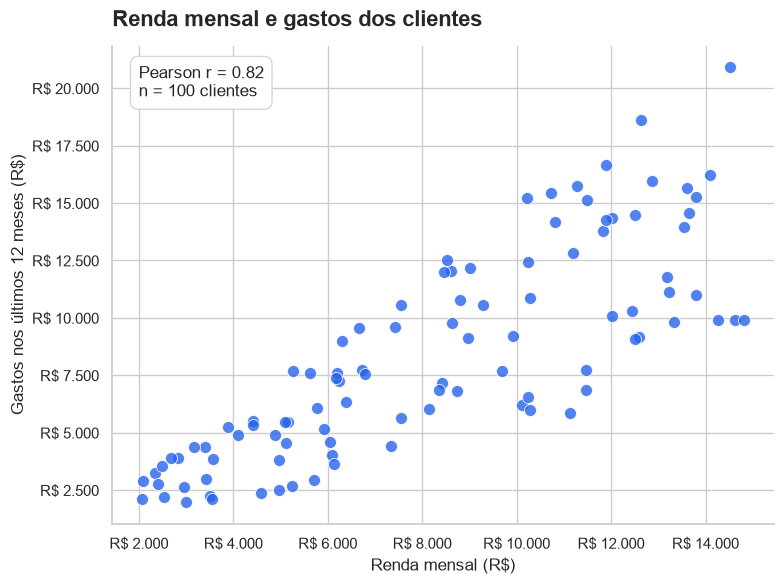

In [3]:
df = raw_data.copy()

x_col = "renda_mensal"
y_col = "valor_total_compras"

dados = df[[x_col, y_col]].dropna()
pearson = dados[x_col].corr(dados[y_col], method="pearson")

def formatar_moeda(valor, _):
    return f"R$ {valor:,.0f}".replace(",", "X").replace(".", ",").replace("X", ".")

sns.set_theme(style="whitegrid", context="notebook")
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=dados,
    x=x_col,
    y=y_col,
    ax=ax,
    s=75,
    alpha=0.8,
    color="#2563EB",
    edgecolor="white",
)

ax.set_title("Renda mensal e gastos dos clientes", loc="left",
             fontsize=16, fontweight="bold", pad=14)
ax.set_xlabel("Renda mensal (R$)")
ax.set_ylabel("Gastos nos últimos 12 meses (R$)")
ax.xaxis.set_major_formatter(FuncFormatter(formatar_moeda))
ax.yaxis.set_major_formatter(FuncFormatter(formatar_moeda))

ax.text(
    0.04, 0.96,
    f"Pearson r = {pearson:.2f}\nn = {len(dados)} clientes",
    transform=ax.transAxes,
    va="top",
    bbox={"boxstyle": "round,pad=0.5", "facecolor": "white",
          "edgecolor": "#D1D5DB", "alpha": 0.95},
)

sns.despine()
plt.tight_layout()
plt.show()

### Q2 - Quanto **mais tempo** um cliente é ativo, maior a sua frequência de **compras**?

Sim. É possível observar essa tendência através do gráfico de dispersão entre as duas variáveis. E, o coeficiente linear de pearson revelou uma **correlação linear forte e positiva** (r=0,84).

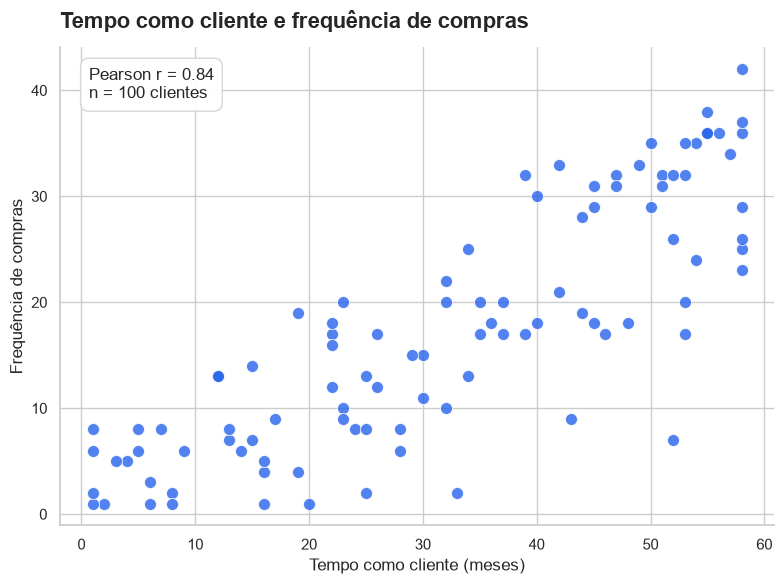

In [4]:
x_col = "tempo_cliente"
y_col = "frequencia_compras"

dados = df[[x_col, y_col]].dropna()
pearson = dados[x_col].corr(dados[y_col], method="pearson")

sns.set_theme(style="whitegrid", context="notebook")
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=dados,
    x=x_col,
    y=y_col,
    ax=ax,
    s=75,
    alpha=0.8,
    color="#2563EB",
    edgecolor="white",
)

ax.set_title(
    "Tempo como cliente e frequência de compras",
    loc="left",
    fontsize=16,
    fontweight="bold",
    pad=14,
)
ax.set_xlabel("Tempo como cliente (meses)")
ax.set_ylabel("Frequência de compras")

ax.text(
    0.04,
    0.96,
    f"Pearson r = {pearson:.2f}\nn = {len(dados)} clientes",
    transform=ax.transAxes,
    va="top",
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "white",
        "edgecolor": "#D1D5DB",
        "alpha": 0.95,
    },
)

sns.despine()
plt.tight_layout()
plt.show()

### Q3 - O **tempo de navegação** influencia o **valor das compras**?

Sim. As duas variáveis estão **fortemente relacionadas negativamente**. Ou seja, **há uma tendência linear em gastar menos quando se passa mais tempo navegando**. É importante ressaltar que a correlação nem sempre resulta em causalidade. Dessa forma, não podemos afirmar que passar menos tempo navegando resulta em menos gastos.

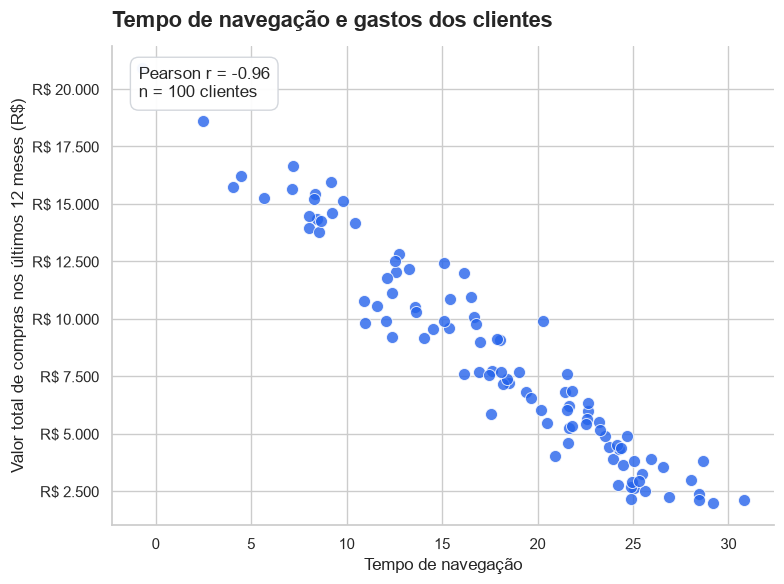

In [5]:
x_col = "tempo_navegacao"
y_col = "valor_total_compras"

dados = df[[x_col, y_col]].dropna()
pearson = dados[x_col].corr(dados[y_col], method="pearson")

def formatar_moeda(valor, _):
    return f"R$ {valor:,.0f}".replace(",", "X").replace(".", ",").replace("X", ".")

sns.set_theme(style="whitegrid", context="notebook")
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=dados,
    x=x_col,
    y=y_col,
    ax=ax,
    s=75,
    alpha=0.8,
    color="#2563EB",
    edgecolor="white",
)

ax.set_title(
    "Tempo de navegação e gastos dos clientes",
    loc="left",
    fontsize=16,
    fontweight="bold",
    pad=14,
)
ax.set_xlabel("Tempo de navegação")
ax.set_ylabel("Valor total de compras nos últimos 12 meses (R$)")
ax.yaxis.set_major_formatter(FuncFormatter(formatar_moeda))

ax.text(
    0.04,
    0.96,
    f"Pearson r = {pearson:.2f}\nn = {len(dados)} clientes",
    transform=ax.transAxes,
    va="top",
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "white",
        "edgecolor": "#D1D5DB",
        "alpha": 0.95,
    },
)

sns.despine()
plt.tight_layout()
plt.show()

### Q4 - Clientes antigos tendem a ter maior satisfação?

Não conseguimos concluir através do gráfico de dispersão. O coeficiente linear de pearson se manteve próximo de zero, indicando ausência de uma relação linear entre essas duas variáveis numéricas. Isso é um indício de que a relação entre essa variáveis não é linear e é necessário uma avaliação mais complexa para identificar certo padrão aqui.

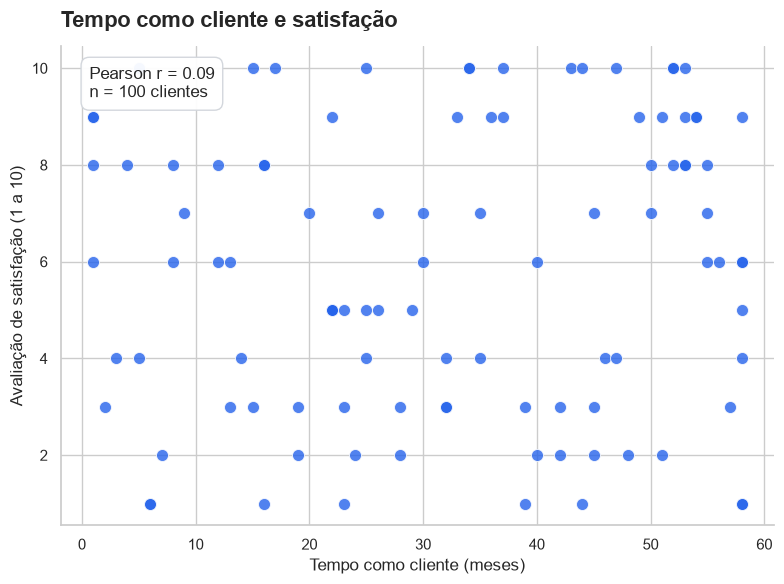

In [6]:
x_col = "tempo_cliente"
y_col = "avaliacao_satisfacao"

dados = df[[x_col, y_col]].dropna()
pearson = dados[x_col].corr(dados[y_col], method="pearson")

sns.set_theme(style="whitegrid", context="notebook")
fig, ax = plt.subplots(figsize=(8, 6))

sns.scatterplot(
    data=dados,
    x=x_col,
    y=y_col,
    ax=ax,
    s=75,
    alpha=0.8,
    color="#2563EB",
    edgecolor="white",
)

ax.set_title(
    "Tempo como cliente e satisfação",
    loc="left",
    fontsize=16,
    fontweight="bold",
    pad=14,
)
ax.set_xlabel("Tempo como cliente (meses)")
ax.set_ylabel("Avaliação de satisfação (1 a 10)")

ax.text(
    0.04,
    0.96,
    f"Pearson r = {pearson:.2f}\nn = {len(dados)} clientes",
    transform=ax.transAxes,
    va="top",
    bbox={
        "boxstyle": "round,pad=0.5",
        "facecolor": "white",
        "edgecolor": "#D1D5DB",
        "alpha": 0.95,
    },
)

sns.despine()
plt.tight_layout()
plt.show()

### Q5 - Qual é o nível de associação entre tempo de cliente e avaliação?

O nível de associação entre essa variáveis é **moderado** (IV = 0,2266). Ao analisar as % de Alto grau de satisfação nas categorias de tempo de cliente, conseguimos entender que a relação não segue uma relação monotônica, ou seja, um relação que aumenta conforme a outra aumenta. É uma relação em formato de "U" e corresponde com o valor da correlação de pearson calculado na questão anterior.

Para responder essa questão, será realizado o cálculo do *Information Value (IV)* entre a variável binária `satisfacao` que indicia se o nível de satisfação do cliente em alto ou baixo e a variável `faixa_tempo_cliente`. 

O **Information Value (IV)** atua como uma medida exploratória para comparar o poder de separação de cada variável em relação à resposta. Para cada categoria *i* da variável, calcula-se o WoE (***Weight of Evidence***) e a contribuição parcial ao IV. Ele é calculado a partir de:

$$
\mathrm{IV} = \sum_i \left(\%\,\mathrm{Alta}_i - \%\,\mathrm{Baixa}_i\right)\times \mathrm{WoE}_i
$$

Nesta análise, o WoE é calculado como o logaritmo natural da proporção entre satisfação alta (**%Event**) em relação à proporção das satisfações baixas (**%NonEvent**), em cada categoria:

$$
\mathrm{WoE}_i = \ln\left(\frac{\%\,\mathrm{Alta}_i}{\%\,\mathrm{Baixa}_i}\right)
$$

onde:
- **% Altaᵢ**: proporção dos clientes que **tiveram o alto grau de satisfação** e pertencem à categoria *i*.
- **% Baixaᵢ**: proporção dos clientes que **tiveram um baixo grau de satisfação** e pertencem à categoria *i*.

> O WoE também pode ser chamado de Ln(Odds), onde Odds é razão entre os eventos binários seguindo a convenção para os cálculos.

Os valores de IV foram interpretados de forma aproximada segundo as faixas abaixo:
| Faixa de IV | Interpretação |
|:---:|:---:|
| < 0,02 | Muito fraco |
| Entre 0,02 e 0,10 | Fraco |
| Entre 0,10 e 0,30 | Médio |
| Entre 0,30 e 0,50 | Forte |
| Maior que 0,50 | Suspeito ou muito alto; recomenda-se verificar |


In [7]:
# Satisfação binária: notas de 1 a 6 = baixa; de 7 a 10 = alta
df["satisfacao"] = pd.cut(
    df["avaliacao_satisfacao"],
    bins=[0, 6, 10],
    labels=["baixa", "alta"]
)

# Tempo como cliente em seis faixas
df["faixa_tempo_cliente"] = pd.cut(
    df["tempo_cliente"],
    bins=[1, 12, 22, 32, 42, 52, 62],
    labels=["1-11", "12-21", "22-31", "32-41", "42-51", "52-61"],
    right=False
)

In [8]:
from IPython.display import display

ordem_faixas = ["1-11", "12-21", "22-31", "32-41", "42-51", "52-61"]

base = df[["faixa_tempo_cliente", "satisfacao"]].dropna()

frequencia = pd.crosstab(
    index=base["faixa_tempo_cliente"],
    columns=base["satisfacao"],
    margins=True,
    margins_name="Total",
    dropna=False
).reindex(
    index=ordem_faixas + ["Total"],
    columns=["alta", "baixa", "Total"],
    fill_value=0
)

tabela = frequencia.copy()
contagem_faixas = frequencia.loc[ordem_faixas, ["alta", "baixa"]]

# Percentual de alta e baixa dentro de cada faixa
total_faixa = contagem_faixas.sum(axis=1).replace(0, np.nan)
tabela.loc[ordem_faixas, "% faixa alta"] = contagem_faixas["alta"] / total_faixa
tabela.loc[ordem_faixas, "% faixa baixa"] = contagem_faixas["baixa"] / total_faixa

# Percentuais de cada faixa entre todos os casos de alta e de baixa.
# Aplica correção de 0,5 se alguma faixa não tiver casos de uma classe.
correcao = 0.5 if (contagem_faixas == 0).any().any() else 0
n_faixas = len(ordem_faixas)

pct_alta = (contagem_faixas["alta"] + correcao) / (
    contagem_faixas["alta"].sum() + correcao * n_faixas
)
pct_baixa = (contagem_faixas["baixa"] + correcao) / (
    contagem_faixas["baixa"].sum() + correcao * n_faixas
)

tabela.loc[ordem_faixas, "% alta"] = pct_alta
tabela.loc[ordem_faixas, "% baixa"] = pct_baixa

# Totais das porcentagens e métricas
total_registros = frequencia.loc["Total", "Total"]
tabela.loc["Total", "% alta"] = 1
tabela.loc["Total", "% baixa"] = 1
tabela.loc["Total", "% faixa alta"] = frequencia.loc["Total", "alta"] / total_registros
tabela.loc["Total", "% faixa baixa"] = frequencia.loc["Total", "baixa"] / total_registros

# Odds, LnOdds e IV parcial por faixa
tabela.loc[ordem_faixas, "Odds"] = pct_alta / pct_baixa
tabela.loc[ordem_faixas, "LnOdds"] = np.log(pct_alta / pct_baixa)
tabela.loc[ordem_faixas, "IV parcial"] = (pct_alta - pct_baixa) * np.log(pct_alta / pct_baixa)

tabela.loc["Total", "Odds"] = 1
tabela.loc["Total", "LnOdds"] = 0
tabela.loc["Total", "IV parcial"] = tabela.loc[ordem_faixas, "IV parcial"].sum()

display(tabela.style.format({
    "% alta": "{:.2%}",
    "% baixa": "{:.2%}",
    "% faixa alta": "{:.2%}",
    "% faixa baixa": "{:.2%}",
    "Odds": "{:.3f}",
    "LnOdds": "{:.3f}",
    "IV parcial": "{:.4f}"
}))

satisfacao,alta,baixa,Total,% faixa alta,% faixa baixa,% alta,% baixa,Odds,LnOdds,IV parcial
faixa_tempo_cliente,,,,,,,,,,
1-11,7,8,15,46.67%,53.33%,15.91%,14.29%,1.114,0.108,0.0017
12-21,6,8,14,42.86%,57.14%,13.64%,14.29%,0.955,-0.047,0.0003
22-31,4,14,18,22.22%,77.78%,9.09%,25.00%,0.364,-1.012,0.1609
32-41,7,8,15,46.67%,53.33%,15.91%,14.29%,1.114,0.108,0.0017
42-51,8,9,17,47.06%,52.94%,18.18%,16.07%,1.131,0.123,0.0026
52-61,12,9,21,57.14%,42.86%,27.27%,16.07%,1.697,0.529,0.0592
Total,44,56,100,44.00%,56.00%,100.00%,100.00%,1.000,0.000,0.2266


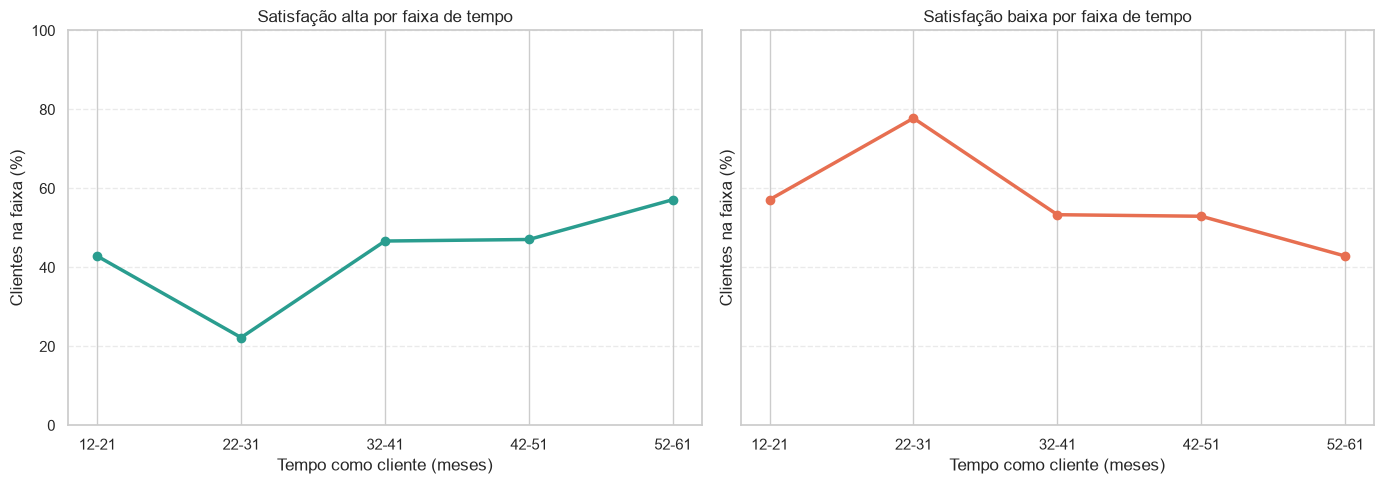

In [10]:
ordem_faixas = ["2-11", "12-21", "22-31", "32-41", "42-51", "52-61"]

# Conta clientes por faixa e nível de satisfação
contagens = pd.crosstab(
    df["faixa_tempo_cliente"],
    df["satisfacao"]
).reindex(
    index=ordem_faixas,
    columns=["alta", "baixa"],
    fill_value=0
)

# Calcula o percentual de cada nível dentro de cada faixa de tempo
total_por_faixa = contagens.sum(axis=1).replace(0, np.nan)
percentuais = contagens.div(total_por_faixa, axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

graficos = [
    ("alta", "Satisfação alta por faixa de tempo", "#2A9D8F"),
    ("baixa", "Satisfação baixa por faixa de tempo", "#E76F51"),
]

for ax, (nivel, titulo, cor) in zip(axes, graficos):
    ax.plot(
        ordem_faixas,
        percentuais[nivel],
        marker="o",
        linewidth=2.5,
        color=cor,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Tempo como cliente (meses)")
    ax.set_ylabel("Clientes na faixa (%)")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# 4. Correlação é diferente de Causalidade

É importante compreender a diferença entre esses dois conceitos para evitar interpretações equivocadas dos dados em análises estatísticas e analytics.

**Correlação** é uma medida estatística que quantifica a intensidade e, dependendo do coeficiente utilizado, a direção da associação entre duas variáveis. Já a **causalidade** representa uma relação de causa e efeito, na qual uma alteração em uma variável pode produzir uma alteração em outra.

De modo geral, **correlação não implica causalidade**. Duas variáveis podem apresentar uma associação estatística sem que uma seja responsável por causar alterações na outra.

Essa associação pode decorrer de variáveis de confusão, tendências temporais, coincidências estatísticas ou outros mecanismos.

Portanto, devemos manter uma postura crítica ao interpretar associações estatísticas, especialmente quando buscamos estabelecer relações de causa e efeito.

Antes de assumir causalidade, vale questionar:
- Existe um mecanismo plausível pelo qual a variável A poderia causar alterações na variável B?
- Poderia existir uma terceira variável influenciando ambas?
- A causa proposta ocorre antes do efeito?
- Existem evidências experimentais ou métodos de inferência causal que sustentem essa interpretação?

Para estudar a causalidade é necessário aplicar técnicas de **inferência causal**.

# 5. Considerações Finais

Neste notebook, foi abordado como avaliar a correlação entre variáveis numéricas a partir de **gráficos de dispersão** e o cálculo do **coeficiente linear de pearson**. Além disso, foi possível implementar a análise com o *information value (IV)* uma vez que realizamos a discretização da variável `tempo_cliente` e transformamos a variável `avaliacao_satisfacao` em uma variável binária. Também, pudemos observar parte do processo da **análise bivariada** que busca identificar padrões entre duas variáveis.

Por fim, é importante repetir que as análises de correlação e associação não nos permite concluir que uma variável cause a outra, sendo necessário aplicar outros tipos de testes para conseguirmos identificar a causalidade.